#### 복습
- LLM = 대규모 언어 모델 (언 어!!)
- 에이전트 = 특정 작업을 수행하는 주체 (모델, 도구, 실행절차를 가진 주체...)
- Tool = 에이전트가 사용하는 도구 (예: 데이터베이스, API, 파일 시스템 등)
- State = 그래프에서 전체적으로 값을 기억하고 기록하는 역할
- Node = 그래프에서 상태를 나타내는 단위(내부적으론 함수로 나타냄)
- Edge = 그래프에서 노드 간의 관계를 나타내는 단위
- 노드와 에이전트의 차이점:
    - 노드: 그래프 안에서 실행단이 1개임
        - 노드는 llm이 들어있을수도 있고 단순한 함수일 수도 있음(안들어있을수도 있다는 말)
    - 에이전트: 목표를 가지고 실행할 수 있는 시스템이고 노드를 포함할 수 있음
        - 에이전트는 무조건 llm을 가지고 있어야 함
        - 즉, 에이전트는 여러 노드를 조합하여 복잡한 작업을 수행할 수 있음

![복습이미지](./images/ref/06_01.png)

___
```Markdown - 서론
이제는 시작이 있으면 llm에게 질문을 던지고 이 llm자체가 '검색이 필요한데?'하고 검색을 할건데
이 검색하는 툴 중에(Tavli...말고도 여러개 많음) 어떤 툴을 사용할지 llm이 판단해서 검색을 수행하게 될 것임

그럼 저 검색툴도 노드로 등록되어야 있어야 했는데
에이전트를 하나 만들어서 검색 엔진을 다 집어넣어두고
하나의 특정 전문 분야들끼리 묶어 에이전트를 만들고?

그 여러 에이전트들을 = 전문가 집단을 만들어 협업하게 할 수 있음!!
```

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움!
- Multi Agent는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달함~!! (전문가 집단!)
    - [Multi Agent 종류]
    - Network: 동료 간 상호 위임이 가능한 연결 구조(거미줄처럼 연결되어있음)
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자(나머지 에이전트를 컨트롤하는 심판 역할)
    - Hierarchical: 팀 안에 팀이 있는 계층적인 조직(Supervisor 확장판으로, 여러 계층의 관리자가 존재함)
    - Custom: 특정 요구사항에 맞게 설계된 맞춤형 구조(내가 만들고싶은 상태로 수정해서 만드는~~ | 위 3개가 기본적인거임)


### **1-1. 용어 설명**

#### 1-1-1. HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것
- 그래프상에서 에이전트가 서로 다른 경우를 말하는데, 한 에이전트가 수행하던 작업을 다른 에이전트가 이어받아 수행하게 되는 상황을 의미함.

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [ ]:
# 에이전트 간 공유할 상태
class HandoffState(TypedDict, total=False):
    request: str        # 사용자 요청
    department: str     # 담당 부서
    answer: str         # 답변

# 요청 내용에 따라 담당 부서 결정
def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

# 코딩 담당: 코드 예제 반환
def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

# 글쓰기 담당: 글 구성 안내 반환
def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

# 결정된 담당 부서로 이동할 경로 반환
def route_handoff(state: HandoffState):
    return state["department"]

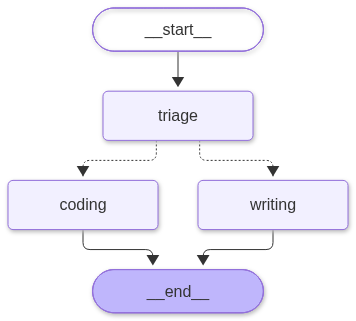

In [ ]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)

handoff_graph = builder.compile()
handoff_graph

In [ ]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [ ]:
# stream_mode="updates": 과정이 보임
# 근데 지금은 단일 에이전트고 멀티에이전트로 바꾸려면 아래 코드셀 확인!
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


In [ ]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [ ]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# ★★ 1. 분류 에이전트(노드 아님!!)
# Command: 실질적으로 Handoff를 실행하는건데 (이게 이제 에이전트들과 주고받기가 가능하게 해주는거임)
# Literal: 특정 값만 허용하도록 타입 지정
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]:
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    # goto: 이동할 에이전트 지정(명령어임) -> 다음에 실행할 노드 지정과 같은 말
    # update: 공유 상태(State)에 department 정보를 저장함
    return Command(update={"department": dept}, goto=dept)


# ★★ 2. 코딩 에이전트(노드 아님!!)
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# ★★ 3. 글쓰기 에이전트(노드 아님!!)
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요. \n요청: {state['request']}"
    )
    return {"answer": response.content}

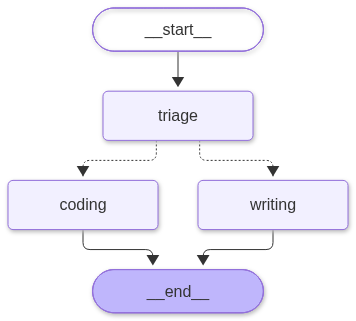

In [ ]:
# 이제 위에걸로 그래프 구성!
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

# 멀티 에이전트에선 add_conditional_edges가 필요 없고, triage에서 바로 각 에이전트로 이동함(goto 사용)
builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph

In [37]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result['department']}")
    print(f"답변: {result['answer']}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: # 파이썬 `for`문이란?

`for`문은 **여러 개의 데이터를 하나씩 꺼내 반복해서 실행**할 때 사용합니다.

## 기본 문법

```python
for 변수 in 반복할_대상:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼내 `fruit`에 저장
2. `print(fruit)` 실행
3. `"바나나"`를 꺼내 실행
4. `"포도"`를 꺼내 실행

---

## `range()`와 함께 사용하기

`range()`는 숫자 범위를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 4까지**의 숫자를 의미합니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

`range(시작, 끝)`에서 **끝 숫자는 포함되지 않습니다.**

---

## 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수 있습니다.

```python
for character in "Python":
    print(character)
```

결과:

```text
P
y
t
h
o
n
```

---

## 합계 구하기

```python
numbers = [10, 20, 30]
total = 0

for number in numbers:
    total = total + number

print(total)
```

결과:

```text
6

![에이전트와 멀티에이전트 차이](./images/ref/06_02.png)

### **1-2. 종류1) Network**
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 한다.

In [57]:
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field  # llm이 값을 줄 때 구조화시켜 줄 수 있도록 하는..
import os, json
import matplotlib.pyplot as plt

In [48]:
load_dotenv()

True

In [49]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env 파일에 OPENAI API KEY가 설정되어 있지 않습니다.")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [50]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

[에이전트를 네트워크형식으로 구현해볼게~]

In [ ]:
# llm에게 지시와 사용자 입력을 구분해서 질문 보냄
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [ ]:
# 차트 상태
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

# 차트 데이터
class ChartData(TypedDict):
    label: str
    value: float

In [64]:
# 웹 검색 함수
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError(".env 파일에 TAVILY API KEY가 설정되어 있지 않습니다.")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{
        "title": x.get("title", ""), 
        "url": x.get("url", ""), 
        "content": x.get("content", "")[:1500]
    } for x in result.get("results", [])]

In [65]:
# llm이 주는 값을 구조화시킴
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만 포함!")
    summary: str

In [66]:
# 구조화된 출력이 가능한 llm 생성함
research_llm = llm.with_structured_output(ResearchData)

In [67]:
# 연구자 역할을 수행해서 검색결과 분석하고, 검증 가능한 수치 추출함
def resercher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    # 사용자 질문 기반으로 웹 검색 수행
    sources = search_web(state["question"])
    # 검색 결과에서 검증 가능한 수치를 추출
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources": sources}, ensure_ascii=False))
    ])

    # parsed 데이터가 없으면 에러 저장 후 종료
    if not parsed.data:
        return Command(update={
            "sources": sources,
            "error": "검증 가능한 수치가 없습니다."
        }, goto=END)
    # 그게 아니라면(데이터가 있다면)
    # 검색 결과, 수치, 요약을 저장하고 차트노드로 이동
    return Command(update={
        "sources": sources,
        "data": [x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data],
        "summary": parsed.summary
    }, goto="chart")

In [68]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

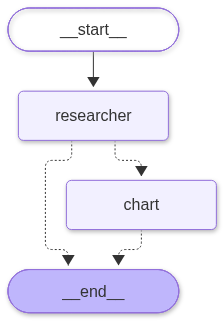

In [69]:
builder = StateGraph(ChartState)

builder.add_node("researcher", resercher)
builder.add_node("chart", chart)
# END를 쓸 필요가 없음
# why?! 
# 위에서 Command(goto=END)를 사용했으니까 여기서 END 정의 안해도됨 쩐다!!

builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

In [71]:
# 맷플로립 한글깨짐 방지
import matplotlib as mpl

# 한글 폰트 설정 (Windows)
mpl.rcParams["font.family"] = "Malgun Gothic"
# 마이너스(-) 기호 깨짐 방지
mpl.rcParams["axes.unicode_minus"] = False

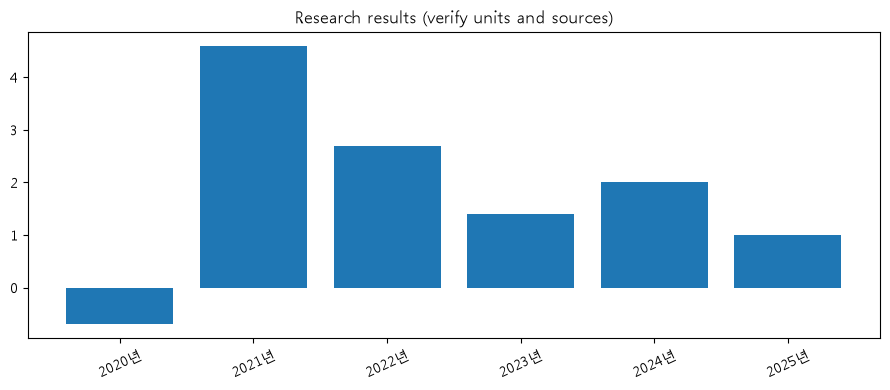

In [72]:
result = network_chart.invoke(
    {"question": "2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, 
    config={"recursion_limit": 5}
)

#### 2-1-1. 실습) 멀티 에이전트 기반(Network) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석해 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템 개발해보기

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 받아 취약 영역에 대한 객관식 문제 생상

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. llm을 이용해 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. llm을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```